In [1]:
import sys
print(sys.executable) 

C:\Users\LA\construction-ai\env\Scripts\python.exe


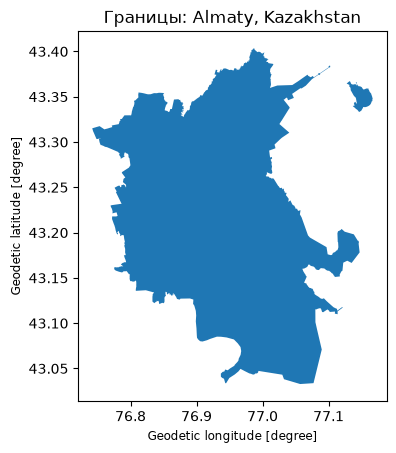

In [2]:
import osmnx as ox
import matplotlib.pyplot as plt

city = "Almaty, Kazakhstan"
gdf = ox.geocode_to_gdf(city)

gdf.plot()
plt.title(f"Границы: {city}")
plt.show()

Найдено зданий: 182338


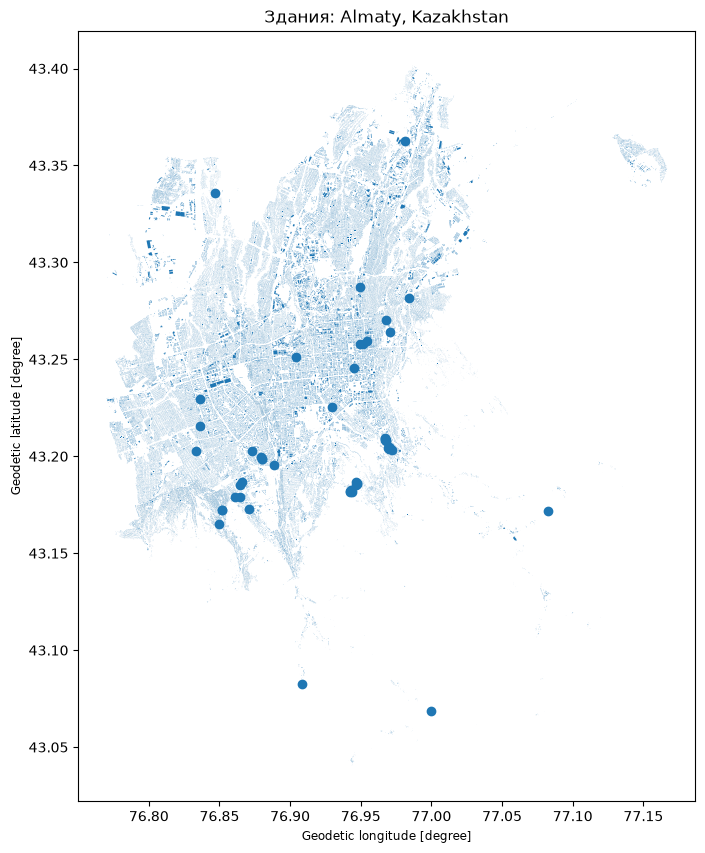

In [3]:
# Посмотрим на здания внутри города
buildings = ox.features_from_place(city, tags={"building": True})
print(f"Найдено зданий: {len(buildings)}")

buildings.plot(figsize=(10,10))
plt.title(f"Здания: {city}")
plt.show()

In [4]:
import requests

# Координаты центра Алматы
lat, lon = 43.2220, 76.8512

response = requests.get(f"https://api.open-meteo.com/v1/elevation?latitude={lat}&longitude={lon}")
elevation = response.json()
print(f"Высота над уровнем моря: {elevation}")

Высота над уровнем моря: {'elevation': [852.0]}


In [5]:
def analyze_site(lat, lon):
    """Базовый анализ участка по координатам"""
    
    # Высота над уровнем моря
    response = requests.get(f"https://api.open-meteo.com/v1/elevation?latitude={lat}&longitude={lon}")
    elevation = response.json()['elevation'][0]
    
    # Простая оценка: Алматы на уклоне, чем выше — тем круче рельеф (условно)
    # Город в среднем на высоте 700-900м
    if elevation < 750:
        risk_note = "Низина — возможен риск подтопления"
    elif elevation > 900:
        risk_note = "Возвышенность — возможен сильный уклон"
    else:
        risk_note = "Средняя зона — относительно стабильный рельеф"
    
    return {
        "координаты": (lat, lon),
        "высота_м": elevation,
        "примечание": risk_note
    }

# Тестируем на нескольких точках Алматы
test_points = [
    (43.2220, 76.8512),  # центр
    (43.1800, 76.8900),  # юг (ближе к горам)
    (43.3200, 76.9200),  # север
]

for point in test_points:
    result = analyze_site(*point)
    print(result)

{'координаты': (43.222, 76.8512), 'высота_м': 852.0, 'примечание': 'Средняя зона — относительно стабильный рельеф'}
{'координаты': (43.18, 76.89), 'высота_м': 1051.0, 'примечание': 'Возвышенность — возможен сильный уклон'}
{'координаты': (43.32, 76.92), 'высота_м': 711.0, 'примечание': 'Низина — возможен риск подтопления'}


In [6]:
# Скачиваем дорожную сеть Алматы (может занять 20-40 секунд)
roads = ox.graph_from_place(city, network_type="drive")
roads_gdf = ox.graph_to_gdfs(roads, nodes=False, edges=True)
print(f"Найдено дорожных сегментов: {len(roads_gdf)}")

Найдено дорожных сегментов: 48740


In [7]:
from shapely.geometry import Point

def distance_to_nearest_road(lat, lon, roads_gdf):
    point = Point(lon, lat)
    distances = roads_gdf.geometry.distance(point)
    nearest_dist_deg = distances.min()
    # Переводим градусы в примерные метры (грубое приближение для широты Алматы)
    nearest_dist_m = nearest_dist_deg * 111000
    return round(nearest_dist_m, 1)

# Тест на той же точке в центре
dist = distance_to_nearest_road(43.2220, 76.8512, roads_gdf)
print(f"Расстояние до ближайшей дороги: {dist} м")

Расстояние до ближайшей дороги: 81.8 м


C:\Users\LA\AppData\Local\Temp\ipykernel_50500\273476866.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  distances = roads_gdf.geometry.distance(point)


In [8]:
import pandas as pd

def analyze_site_full(lat, lon, roads_gdf):
    # Высота
    response = requests.get(f"https://api.open-meteo.com/v1/elevation?latitude={lat}&longitude={lon}")
    elevation = response.json()['elevation'][0]
    
    # Расстояние до дороги
    road_dist = distance_to_nearest_road(lat, lon, roads_gdf)
    
    return {
        "lat": lat,
        "lon": lon,
        "высота_м": elevation,
        "расст_до_дороги_м": road_dist
    }

# Соберём данные по нескольким точкам Алматы
points = [
    (43.2220, 76.8512),
    (43.1800, 76.8900),
    (43.3200, 76.9200),
    (43.2500, 76.9000),
    (43.2000, 76.8700),
]

data = [analyze_site_full(lat, lon, roads_gdf) for lat, lon in points]
df = pd.DataFrame(data)
print(df)

C:\Users\LA\AppData\Local\Temp\ipykernel_50500\273476866.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  distances = roads_gdf.geometry.distance(point)


      lat      lon  высота_м  расст_до_дороги_м
0  43.222  76.8512     852.0               81.8
1  43.180  76.8900    1051.0               18.2
2  43.320  76.9200     711.0                9.4
3  43.250  76.9000     788.0                4.0
4  43.200  76.8700     954.0               55.4


In [9]:
# Перепроецируем дороги в метрическую систему координат (убирает предупреждение и делает расчёт точнее)
roads_gdf_proj = roads_gdf.to_crs(epsg=32642)  # UTM zone для Казахстана

def distance_to_nearest_road_v2(lat, lon, roads_gdf_proj):
    point = gpd.GeoSeries([Point(lon, lat)], crs="EPSG:4326").to_crs(epsg=32642).iloc[0]
    distances = roads_gdf_proj.geometry.distance(point)
    return round(distances.min(), 1)

# Проверка
import geopandas as gpd
dist = distance_to_nearest_road_v2(43.2220, 76.8512, roads_gdf_proj)
print(f"Расстояние до дороги (точный расчёт): {dist} м")

Расстояние до дороги (точный расчёт): 78.0 м


In [10]:
import numpy as np

# Границы Алматы (примерные, из gdf который мы скачали в начале)
bounds = gdf.total_bounds  # [minx, miny, maxx, maxy]
min_lon, min_lat, max_lon, max_lat = bounds

# Генерируем сетку из 50 случайных точек внутри границ города
np.random.seed(42)
n_points = 50
random_lats = np.random.uniform(min_lat, max_lat, n_points)
random_lons = np.random.uniform(min_lon, max_lon, n_points)

print(f"Сгенерировано {n_points} точек")
print(f"Пример первых 3: {list(zip(random_lats[:3], random_lons[:3]))}")

Сгенерировано 50 точек
Пример первых 3: [(np.float64(43.17176893250909), np.float64(77.1538363271686)), (np.float64(43.38548455689075), np.float64(77.07125159579871)), (np.float64(43.304356383685175), np.float64(77.14105877377659))]


In [11]:
import time

def analyze_site_v2(lat, lon, roads_gdf_proj):
    try:
        response = requests.get(f"https://api.open-meteo.com/v1/elevation?latitude={lat}&longitude={lon}")
        elevation = response.json()['elevation'][0]
        road_dist = distance_to_nearest_road_v2(lat, lon, roads_gdf_proj)
        return {"lat": lat, "lon": lon, "высота_м": elevation, "расст_до_дороги_м": road_dist}
    except Exception as e:
        return None

# Собираем данные по всем 50 точкам (займёт 1-2 минуты, идут запросы к API)
results = []
for i, (lat, lon) in enumerate(zip(random_lats, random_lons)):
    result = analyze_site_v2(lat, lon, roads_gdf_proj)
    if result:
        results.append(result)
    if (i+1) % 10 == 0:
        print(f"Обработано {i+1}/{len(random_lats)}")
    time.sleep(0.2)  # небольшая пауза, чтобы не перегружать бесплатный API

dataset = pd.DataFrame(results)
print(f"\nГотово! Собрано {len(dataset)} строк")
dataset.head(10)

Обработано 10/50
Обработано 20/50
Обработано 30/50
Обработано 40/50
Обработано 50/50

Готово! Собрано 50 строк


,lat,lon,высота_м,расст_до_дороги_м
0,43.171769,77.153836,2223.0,4973.0
1,43.385485,77.071252,661.0,4517.5
2,43.304356,77.141059,902.0,8247.6
3,43.254899,77.122087,1503.0,6618.8
4,43.090715,76.995980,2724.0,2073.8
5,43.090706,77.133573,3858.0,8715.0
6,43.054388,76.779632,2357.0,10451.9
7,43.354128,76.825283,696.0,141.9
8,43.255811,76.761257,759.0,1390.0
9,43.295483,76.880218,735.0,63.9


In [12]:
from shapely.geometry import Point

# Берём реальную форму города (полигон), а не просто прямоугольник
city_polygon = gdf.geometry.iloc[0]

def is_inside_city(lat, lon, polygon):
    point = Point(lon, lat)
    return polygon.contains(point)

# Фильтруем только те точки, что реально внутри города
dataset["внутри_города"] = dataset.apply(
    lambda row: is_inside_city(row["lat"], row["lon"], city_polygon), axis=1
)

print(f"Точек внутри реальных границ города: {dataset['внутри_города'].sum()} из {len(dataset)}")
dataset_clean = dataset[dataset["внутри_города"]].reset_index(drop=True)
dataset_clean

Точек внутри реальных границ города: 19 из 50


,lat,lon,высота_м,расст_до_дороги_м,внутри_города
0,43.090715,76.995980,2724.0,2073.8,True
1,43.295483,76.880218,735.0,63.9,True
2,43.100873,76.972534,2699.0,1491.3,True
3,43.168735,77.088379,2147.0,1346.5,True
4,43.202010,77.042255,1574.0,1648.2,True
5,43.106907,77.069611,2723.0,4901.0,True
6,43.223585,76.773496,781.0,491.2,True
7,43.252583,76.894291,784.0,138.9,True
8,43.096095,77.006767,3195.0,3116.9,True
9,43.145832,77.051916,2188.0,888.8,True


In [13]:
# Оставляем только точки в реалистичном диапазоне для городской застройки
dataset_buildable = dataset_clean[dataset_clean["высота_м"] < 1300].reset_index(drop=True)
print(f"Точек в зоне потенциальной застройки: {len(dataset_buildable)} из {len(dataset_clean)}")
dataset_buildable

Точек в зоне потенциальной застройки: 7 из 19


,lat,lon,высота_м,расст_до_дороги_м,внутри_города
0,43.295483,76.880218,735.0,63.9,True
1,43.223585,76.773496,781.0,491.2,True
2,43.252583,76.894291,784.0,138.9,True
3,43.196106,76.942601,1056.0,100.1,True
4,43.370131,76.980426,659.0,221.6,True
5,43.278588,76.951766,748.0,2.3,True
6,43.225748,76.923627,865.0,70.3,True


In [14]:
# Увеличиваем выборку и сразу фильтруем по реальным границам + разумной высоте
np.random.seed(42)
n_points = 300
random_lats = np.random.uniform(min_lat, max_lat, n_points)
random_lons = np.random.uniform(min_lon, max_lon, n_points)

# Сразу фильтруем по городу и высоте, чтобы не тратить время на горы
valid_points = []
for lat, lon in zip(random_lats, random_lons):
    if is_inside_city(lat, lon, city_polygon):
        valid_points.append((lat, lon))

print(f"Точек внутри города (до фильтра по высоте): {len(valid_points)}")

Точек внутри города (до фильтра по высоте): 137


In [15]:
results = []
for i, (lat, lon) in enumerate(valid_points):
    result = analyze_site_v2(lat, lon, roads_gdf_proj)
    if result and result["высота_м"] < 1300:  # сразу фильтруем горы
        results.append(result)
    if (i+1) % 20 == 0:
        print(f"Обработано {i+1}/{len(valid_points)}")
    time.sleep(0.15)

dataset = pd.DataFrame(results)
print(f"\nГотово! Итоговый датасет: {len(dataset)} точек в зоне застройки")
dataset.head()

Обработано 20/137
Обработано 40/137
Обработано 60/137
Обработано 80/137
Обработано 100/137
Обработано 120/137

Готово! Итоговый датасет: 88 точек в зоне застройки


,lat,lon,высота_м,расст_до_дороги_м
0,43.304356,76.971659,708.0,53.8
1,43.254899,77.012768,1017.0,165.4
2,43.295483,76.857072,728.0,18.3
3,43.227487,76.815648,798.0,5.5
4,43.193062,76.808488,867.0,20.7


In [16]:
# Перепроецируем здания в метрическую систему (как делали с дорогами)
buildings_proj = buildings.to_crs(epsg=32642)

def building_density(lat, lon, buildings_proj, radius_m=300):
    point = gpd.GeoSeries([Point(lon, lat)], crs="EPSG:4326").to_crs(epsg=32642).iloc[0]
    buffer = point.buffer(radius_m)
    nearby = buildings_proj[buildings_proj.intersects(buffer)]
    return len(nearby)

# Добавляем признак в датасет (это займёт время — 88 точек, каждая сравнивается с 182к зданий)
densities = []
for i, row in dataset.iterrows():
    d = building_density(row["lat"], row["lon"], buildings_proj)
    densities.append(d)
    if (i+1) % 20 == 0:
        print(f"Обработано {i+1}/{len(dataset)}")

dataset["плотность_застройки"] = densities
print("Готово!")
dataset.head()

Обработано 20/88
Обработано 40/88
Обработано 60/88
Обработано 80/88
Готово!


,lat,lon,высота_м,расст_до_дороги_м,плотность_застройки
0,43.304356,76.971659,708.0,53.8,132
1,43.254899,77.012768,1017.0,165.4,11
2,43.295483,76.857072,728.0,18.3,259
3,43.227487,76.815648,798.0,5.5,208
4,43.193062,76.808488,867.0,20.7,109


In [17]:
def calculate_suitability_score(row):
    score = 100
    
    # Штраф за удалённость от дорог (чем дальше, тем хуже)
    if row["расст_до_дороги_м"] > 500:
        score -= 30
    elif row["расст_до_дороги_м"] > 200:
        score -= 15
    
    # Штраф за экстремальную высоту (неудобный рельеф)
    if row["высота_м"] > 1100:
        score -= 20
    elif row["высота_м"] < 700:
        score -= 10
    
    # Штраф за слишком высокую ИЛИ слишком низкую плотность
    if row["плотность_застройки"] < 20:
        score -= 15  # мало инфраструктуры рядом
    elif row["плотность_застройки"] > 250:
        score -= 10  # уже сильно перегружено
    
    return max(score, 0)

dataset["score_пригодности"] = dataset.apply(calculate_suitability_score, axis=1)
print(dataset[["высота_м", "расст_до_дороги_м", "плотность_застройки", "score_пригодности"]].describe())
dataset.sort_values("score_пригодности", ascending=False).head(10)

          высота_м  расст_до_дороги_м  плотность_застройки  score_пригодности
count    88.000000          88.000000            88.000000          88.000000
mean    831.670455         289.557955           107.886364          85.397727
std     175.165585         722.391150            95.248185          16.819214
min     650.000000           1.100000             0.000000          45.000000
25%     708.750000          18.975000            20.500000          75.000000
50%     754.500000          40.550000            84.500000          90.000000
75%     908.250000         184.125000           201.750000         100.000000
max    1279.000000        4118.200000           328.000000         100.000000


,lat,lon,высота_м,расст_до_дороги_м,плотность_застройки,score_пригодности
0,43.304356,76.971659,708.0,53.8,132,100
3,43.227487,76.815648,798.0,5.5,208,100
5,43.259793,76.975308,800.0,42.0,117,100
4,43.193062,76.808488,867.0,20.7,109,100
15,43.177013,76.906906,1083.0,3.2,98,100
14,43.235631,76.901149,828.0,9.4,118,100
11,43.216516,76.943135,940.0,32.1,168,100
8,43.252583,76.920255,795.0,28.4,87,100
21,43.303249,76.877519,730.0,11.8,177,100
22,43.303471,76.861830,733.0,1.1,204,100


In [18]:
def calculate_suitability_score_v2(row):
    score = 100
    
    # Более строгие и плавные штрафы за расстояние до дороги
    score -= min(row["расст_до_дороги_м"] / 10, 40)  # до -40 баллов
    
    # Штраф за высоту (плавный, не ступенчатый)
    if row["высота_м"] > 1000:
        score -= (row["высота_м"] - 1000) / 10
    elif row["высота_м"] < 700:
        score -= (700 - row["высота_м"]) / 10
    
    # Штраф за плотность застройки (и низкую, и высокую)
    if row["плотность_застройки"] < 30:
        score -= (30 - row["плотность_застройки"]) / 2
    elif row["плотность_застройки"] > 250:
        score -= (row["плотность_застройки"] - 250) / 5
    
    return round(max(score, 0), 1)

dataset["score_пригодности"] = dataset.apply(calculate_suitability_score_v2, axis=1)
print(dataset["score_пригодности"].describe())
dataset.sort_values("score_пригодности", ascending=False).head(10)

count    88.000000
mean     80.777273
std      20.734738
min      17.100000
25%      73.475000
50%      89.750000
75%      96.925000
max      99.900000
Name: score_пригодности, dtype: float64


,lat,lon,высота_м,расст_до_дороги_м,плотность_застройки,score_пригодности
22,43.303471,76.861830,733.0,1.1,204,99.9
77,43.328021,76.851726,709.0,3.4,77,99.7
27,43.318812,76.886790,717.0,4.0,238,99.6
3,43.227487,76.815648,798.0,5.5,208,99.4
14,43.235631,76.901149,828.0,9.4,118,99.1
41,43.217284,76.901003,892.0,9.4,90,99.1
21,43.303249,76.877519,730.0,11.8,177,98.8
37,43.222291,76.791767,791.0,14.5,237,98.6
36,43.336263,76.929569,693.0,11.1,101,98.2
73,43.333054,76.960343,688.0,6.8,85,98.1


In [21]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

# Признаки (X) и целевая переменная (y)
features = ["высота_м", "расст_до_дороги_м", "плотность_застройки"]
X = dataset[features]
y = dataset["score_пригодности"]

# Разделяем на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Обучаем модель
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Проверяем качество на тестовых данных
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Средняя ошибка (MAE): {mae:.2f} баллов")
print(f"R² (качество модели, 1.0 = идеально): {r2:.2f}")

# Важность признаков — что сильнее всего влияет на предсказание
importance = pd.DataFrame({
    "признак": features,
    "важность": model.feature_importances_
}).sort_values("важность", ascending=False)
print("\nВажность признаков:")
print(importance)

Средняя ошибка (MAE): 3.26 баллов
R² (качество модели, 1.0 = идеально): 0.96

Важность признаков:
               признак  важность
1    расст_до_дороги_м  0.769989
2  плотность_застройки  0.134475
0             высота_м  0.095536


In [22]:
import joblib

joblib.dump(model, "site_model.pkl")
print("Модель сохранена в файл site_model.pkl")

Модель сохранена в файл site_model.pkl
